# Propagação de incerteza com PDFs inferidas por UQ[py]Lab

Lemos as cadeias de `11_inference.ipynb`, removemos o burn-in de cada cadeia e recuperamos os parâmetros físicos. A inferência e a seleção das PDFs são feitas por `uqpylab`/UQCloud. Usamos apenas Gaussiana como candidata, exceto para `fmoil` e `floil`, que permitem Gaussiana e Gamma. Amostramos das marginais inferidas com `uq.getSample` e alimentamos os gráficos de espuma deste notebook.

In [1]:
from pathlib import Path
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
import yaml
import json
import os
import copy
from getpass import getpass
from uqpylab import sessions, helpers
import scipy.stats as st
import models.pymc3FoamModel as bayes_model
from IPython.display import display

from models.aux_funcs_01 import (
    load_module, predict, predict_oil, predict_oil_viscosity, evaluate_oil_state,
    predict_oil_at_fg,
)

ROOT = Path.cwd()
if not (ROOT / "inputs/sample3_inputs.yaml").is_file():
    raise FileNotFoundError("Execute o notebook na pasta Vieira2024_v2.")


In [2]:
# Controles: altere N_samples para definir o número de curvas.
N_samples = 100
MCMC_CHAINS_PATH = ROOT / "results/sample3/inference_oil_muApp/mcmc_chains.npz"
FIT_OUTPUT_DIR = MCMC_CHAINS_PATH.parent / "uqpylab_marginals"
UQ_INFERENCE_CRITERION = "BIC"
UQCLOUD_HOST = os.environ.get("UQCLOUD_HOST", "https://uqcloud.ethz.ch")
KDE_MAX_SAMPLES = 10000  # Subamostragem somente para desenhar a KDE; ajuste usa todas as amostras.
PDF_DIAGNOSTIC_SAMPLES = 10000
BASE_SEED = 1
ALPHA = 0.25
SAMPLING_MODE = "resample"  # "resample": N_samples físicos; "discard": N_samples propostas.
FMSURF = 2500
CONCENTRATIONS = (625, 1250, 2500)
N_FG_POINTS = 151
N_SO_POINTS = 100
N_FOIL_POINTS = 501
FG_TARGET = 0.5
FG_TOLERANCE = 1e-6
SATURATION_TOLERANCE = 0.01
N_SATURATION_CANDIDATES = 201
SHOW_NEARBY_CURVES = False  # Curvas locais opcionais, comentadas no código de referência.

FOAM_NAMES = ["fmmob", "epdry", "fmdry", "epsurf", "epoil", "fmoil", "floil"]

with (ROOT / "inputs/sample3_inputs.yaml").open() as f:
    inputs = yaml.safe_load(f)
with (ROOT / "inputs/sample3_experimentalData.yaml").open() as f:
    experiments = yaml.safe_load(f)

fixed_rp_oil = inputs["relPerm"].copy()
fixed_rp_no_oil = {**fixed_rp_oil, "sor": 0.0}
rp_no_oil = np.array([
    fixed_rp_no_oil[key]
    for key in ("nw_", "ng_", "krw0", "krg0", "swc", "sgr", "sor")
], dtype=float)

# Mesma associação entre módulo de espuma e permeabilidade relativa de 01_estimate.
rp_module = load_module("parametric_relperm", str(ROOT / "models/relativePermeabilityModels.py"))
foam_module_oil = load_module("parametric_foam_oil", str(ROOT / "models/foamModels.py"))
foam_module_no_oil = load_module("parametric_foam_no_oil", str(ROOT / "models/foamModels.py"))
foam_module_oil.coreyBrooks3ph = rp_module.coreyBrooks3ph(fixed_rp_oil)
foam_module_no_oil.coreyBrooks3ph = rp_module.coreyBrooks3ph(fixed_rp_no_oil)

scans = {
    cs: np.asarray(experiments[f"FQS_{cs}mgL"]["data"], dtype=float)
    for cs in CONCENTRATIONS
}
velocity_by_concentration = {
    cs: float(experiments[f"FQS_{cs}mgL"]["ut"]) * 0.3048 / 86400
    for cs in CONCENTRATIONS
}
oil_experiment = experiments["oil_observations_preprocessed"]
oil_observations = pd.DataFrame(
    oil_experiment["data"], columns=["So", "Sw", "Sg", "muApp", "fg"],
).sort_values("So").reset_index(drop=True)
so_oil_obs = oil_observations["So"].to_numpy()
sw_oil_obs = oil_observations["Sw"].to_numpy()
sg_oil_obs = oil_observations["Sg"].to_numpy()
mu_oil_obs = oil_observations["muApp"].to_numpy() * 1000  # Pa.s -> cP
cs_oil = float(oil_experiment["surfactant_concentration_mg_L"])
cs_oil_obs = np.full(so_oil_obs.size, cs_oil)


## Cadeias posteriores na escala física

O burn-in é lido do próprio `.npz` e removido **separadamente de cada cadeia**, antes de reuni-las. Aplicamos as mesmas transformações de `11_inference.ipynb`: exponenciais dos parâmetros em log, reconstrução de `fmoil` e raiz quadrada das variâncias para obter `sigma_surf` e `sigma_oil`. `physical_posterior` preserva os eixos `(chain, draw, parameter)`; `posterior_df` reúne as amostras para ajustar uma marginal por parâmetro.

In [3]:
expected_names = list(bayes_model.COORDINATE_NAMES) + ["variance_surf", "variance_oil"]
posterior_names = list(bayes_model.FOAM_NAMES) + ["sigma_surf", "sigma_oil"]
with np.load(MCMC_CHAINS_PATH, allow_pickle=False) as saved:
    if saved["names"].tolist() != expected_names:
        raise ValueError("Nomes ou ordem dos parâmetros MCMC incompatíveis.")
    raw_chains = saved["raw_chains"]
    MCMC_BURNIN = int(saved["burnin"])
if (raw_chains.ndim != 3 or raw_chains.shape[1] != len(expected_names)
        or raw_chains.shape[2] < 1 or not 0 <= MCMC_BURNIN < raw_chains.shape[0]):
    raise ValueError("Formato das cadeias ou burn-in inválido.")
raw_posterior = np.moveaxis(raw_chains[MCMC_BURNIN:], 2, 0)
if not np.isfinite(raw_posterior).all() or np.any(raw_posterior[..., 7:] <= 0):
    raise ValueError("Posterior com valores não finitos ou variâncias não positivas.")
physical_posterior = np.concatenate([
    bayes_model.decode_parameters(raw_posterior[..., :7]),
    np.sqrt(raw_posterior[..., 7:]),
], axis=-1)
posterior_df = pd.DataFrame(
    physical_posterior.reshape(-1, len(posterior_names)), columns=posterior_names,
)
mcmc_statistics = posterior_df.agg(["mean", "std"]).T
mcmc_statistics.index.name = "parameter"
mcmc_statistics["cv_percent"] = 100 * mcmc_statistics["std"] / mcmc_statistics["mean"].abs()
print(f"Arquivo: {MCMC_CHAINS_PATH}")
print(f"Burn-in por cadeia: {MCMC_BURNIN}; cadeias: {physical_posterior.shape[0]}; draws posteriores por cadeia: {physical_posterior.shape[1]}")
print(f"Total de amostras usadas em cada ajuste: {len(posterior_df)}")
print(mcmc_statistics.to_string(float_format=lambda value: f"{value:.6g}"))


Arquivo: /home/anderson/inverseFoam/experiments/Vieira2024_v2/results/sample3/inference_oil_muApp/mcmc_chains.npz
Burn-in por cadeia: 5000; cadeias: 4; draws posteriores por cadeia: 20000
Total de amostras usadas em cada ajuste: 80000
                mean        std  cv_percent
parameter                                  
fmmob        80410.8     8128.4     10.1086
epdry        3708.72    1240.75     33.4548
fmdry       0.360559 0.00010417   0.0288912
epsurf       1.44198   0.114182     7.91839
epoil        17.3497    11.0775     63.8481
fmoil       0.782713   0.170905      21.835
floil       0.118112    0.22136     187.415
sigma_surf 0.0840809   0.015014     17.8566
sigma_oil   0.232772    0.17906      76.925


## Inferência das PDFs com UQ[py]Lab

Usamos `sessions.cloud` e `uq.createInput`, passando todas as amostras posteriores de cada parâmetro em `Inference.Data`. As candidatas são `Gaussian` para os demais parâmetros e `['Gaussian', 'Gamma']` para `fmoil` e `floil`. `Inference.Criterion` é configurado como `BIC`; a seleção e os parâmetros são retornados pelo UQCloud, sem ajuste local por SciPy.

A sessão usa `UQCLOUD_HOST` e o token em `UQCLOUD_TOKEN`; se o token não estiver no ambiente nem na configuração do UQ[py]Lab, será solicitado com `getpass`. A execução desta célula envia as amostras ao UQCloud. O token não é gravado no notebook nem nos arquivos de resultados.

Guardamos `Type`, `Parameters`, `Moments` e `GoF` retornados pelo UQCloud. A parametrização Gamma permanece na convenção nativa do UQLab. `uq.getSample` gera os sorteios e `uq.all_pdf` avalia as densidades; SciPy é usado somente para a KDE de referência. As candidatas disponíveis podem aproximar com limitações as posteriores assimétricas.

Referência: [UQ[py]Lab — inferência de marginais](https://storage.googleapis.com/uqpylab-examples-html/Input-6-Infer%20Marginals.html).

In [4]:
# Sessão UQCloud: o token não aparece nas saídas nem é persistido.
uq_config = helpers.uqcloud_load_config()
uq_token = '270fe799b4e4e4f004da79cec3dffb07cf9da78a'
if not uq_token:
    uq_token = getpass("UQCloud token: ").strip()
if not uq_token:
    raise ValueError("Informe UQCLOUD_TOKEN ou digite o token UQCloud quando solicitado.")
mySession = sessions.cloud(host=UQCLOUD_HOST, token=uq_token, log_level="WARNING")
mySession.timeout = 300
uq = mySession.cli
del uq_token
uq.rng(BASE_SEED, "twister")

candidate_types = {
    name: (["Gamma"] if name in {"fmoil", "floil"} else ["Gaussian"])
    for name in posterior_names
}
fitted_marginals = {}
fitted_input_objects = {}
summary_rows = []
for name in posterior_names:
    print(f"Inferindo {name}: {candidate_types[name]} ({len(posterior_df)} amostras)", flush=True)
    options = {
        "Inference": {
            "Data": posterior_df[[name]].to_numpy().tolist(),
            "Criterion": UQ_INFERENCE_CRITERION,
        },
        "Copula": {"Type": "Independent"},
        "Marginals": [{"Name": name, "Type": candidate_types[name]}],
    }
    input_hat = uq.createInput(options)
    marginal = input_hat["Marginals"]
    if isinstance(marginal, list):
        if len(marginal) != 1:
            raise ValueError(f"Número inesperado de marginais para {name}.")
        marginal = marginal[0]
    if marginal["Type"] not in candidate_types[name]:
        raise ValueError(f"Família inesperada retornada pelo UQCloud: {name}.")
    parameters = np.asarray(marginal["Parameters"], dtype=float).reshape(-1)
    moments = np.asarray(marginal["Moments"], dtype=float).reshape(-1)
    if (moments.size < 2 or not np.isfinite(moments[:2]).all() or moments[1] <= 0
            or not np.isfinite(parameters).all()):
        raise ValueError(f"Parâmetros ou momentos inválidos retornados para {name}.")
    fitted_input_objects[name] = input_hat
    fitted_marginals[name] = {
        "Name": name, "Type": marginal["Type"],
        "Parameters": parameters.tolist(), "Moments": moments.tolist(),
        "GoF": copy.deepcopy(marginal.get("GoF", {})),
    }
    summary_rows.append({
        "parameter": name, "family": marginal["Type"],
        "parameters_uqlab": json.dumps(parameters.tolist()),
        "mean": float(moments[0]), "std": float(moments[1]),
        "cv_percent": 100 * float(moments[1]) / abs(float(moments[0])),
    })

fitted_statistics = pd.DataFrame(summary_rows).set_index("parameter").loc[posterior_names]
# Objeto conjunto com as marginais inferidas e cópula independente.
# Passa somente Parameters: UQ[py]Lab não permite Parameters e Moments juntos.
joint_input = uq.createInput({
    "Marginals": [
        {key: copy.deepcopy(fitted_marginals[name][key]) for key in ("Name", "Type", "Parameters")}
        for name in posterior_names
    ],
    "Copula": {"Type": "Independent"},
})
joint_marginals = joint_input["Marginals"]
if isinstance(joint_marginals, dict):
    joint_marginals = [joint_marginals]
print("PDFs inferidas e selecionadas pelo UQCloud:")
print(fitted_statistics.to_string(float_format=lambda value: f"{value:.7g}"))


def json_safe(value):
    if isinstance(value, dict):
        return {str(key): json_safe(item) for key, item in value.items()}
    if isinstance(value, (list, tuple, np.ndarray)):
        return [json_safe(item) for item in value]
    if isinstance(value, np.generic):
        return json_safe(value.item())
    if isinstance(value, float) and not np.isfinite(value):
        return None
    return value


FIT_OUTPUT_DIR.mkdir(parents=True, exist_ok=True)
with (FIT_OUTPUT_DIR / "fitted_marginals.json").open("w") as f:
    json.dump(json_safe({
        "backend": "uqpylab/UQCloud", "host": UQCLOUD_HOST,
        "source": str(MCMC_CHAINS_PATH), "burnin_per_chain": MCMC_BURNIN,
        "n_chains": int(physical_posterior.shape[0]),
        "draws_per_chain": int(physical_posterior.shape[1]),
        "n_samples_per_parameter": len(posterior_df),
        "selection_criterion": UQ_INFERENCE_CRITERION, "proposal_dependence": "independent",
        "candidate_types": candidate_types, "marginals": fitted_marginals,
    }), f, indent=2, allow_nan=False)
fitted_statistics.to_csv(FIT_OUTPUT_DIR / "fitted_statistics.csv", index_label="parameter")


Inferindo fmmob: ['Gaussian'] (80000 amostras)
Inferindo epdry: ['Gaussian'] (80000 amostras)
Inferindo fmdry: ['Gaussian'] (80000 amostras)
Inferindo epsurf: ['Gaussian'] (80000 amostras)
Inferindo epoil: ['Gaussian'] (80000 amostras)
Inferindo fmoil: ['Gamma'] (80000 amostras)
Inferindo floil: ['Gamma'] (80000 amostras)
Inferindo sigma_surf: ['Gaussian'] (80000 amostras)
Inferindo sigma_oil: ['Gaussian'] (80000 amostras)
PDFs inferidas e selecionadas pelo UQCloud:
              family                              parameters_uqlab       mean          std  cv_percent
parameter                                                                                             
fmmob       Gaussian        [80410.82811581843, 8128.402469196522]   80410.83     8128.402    10.10859
epdry       Gaussian      [3708.7231752021967, 1240.7470273242998]   3708.723     1240.747    33.45483
fmdry       Gaussian  [0.3605590645657755, 0.00010416968421567726]  0.3605591 0.0001041697  0.02889116
epsurf      Ga

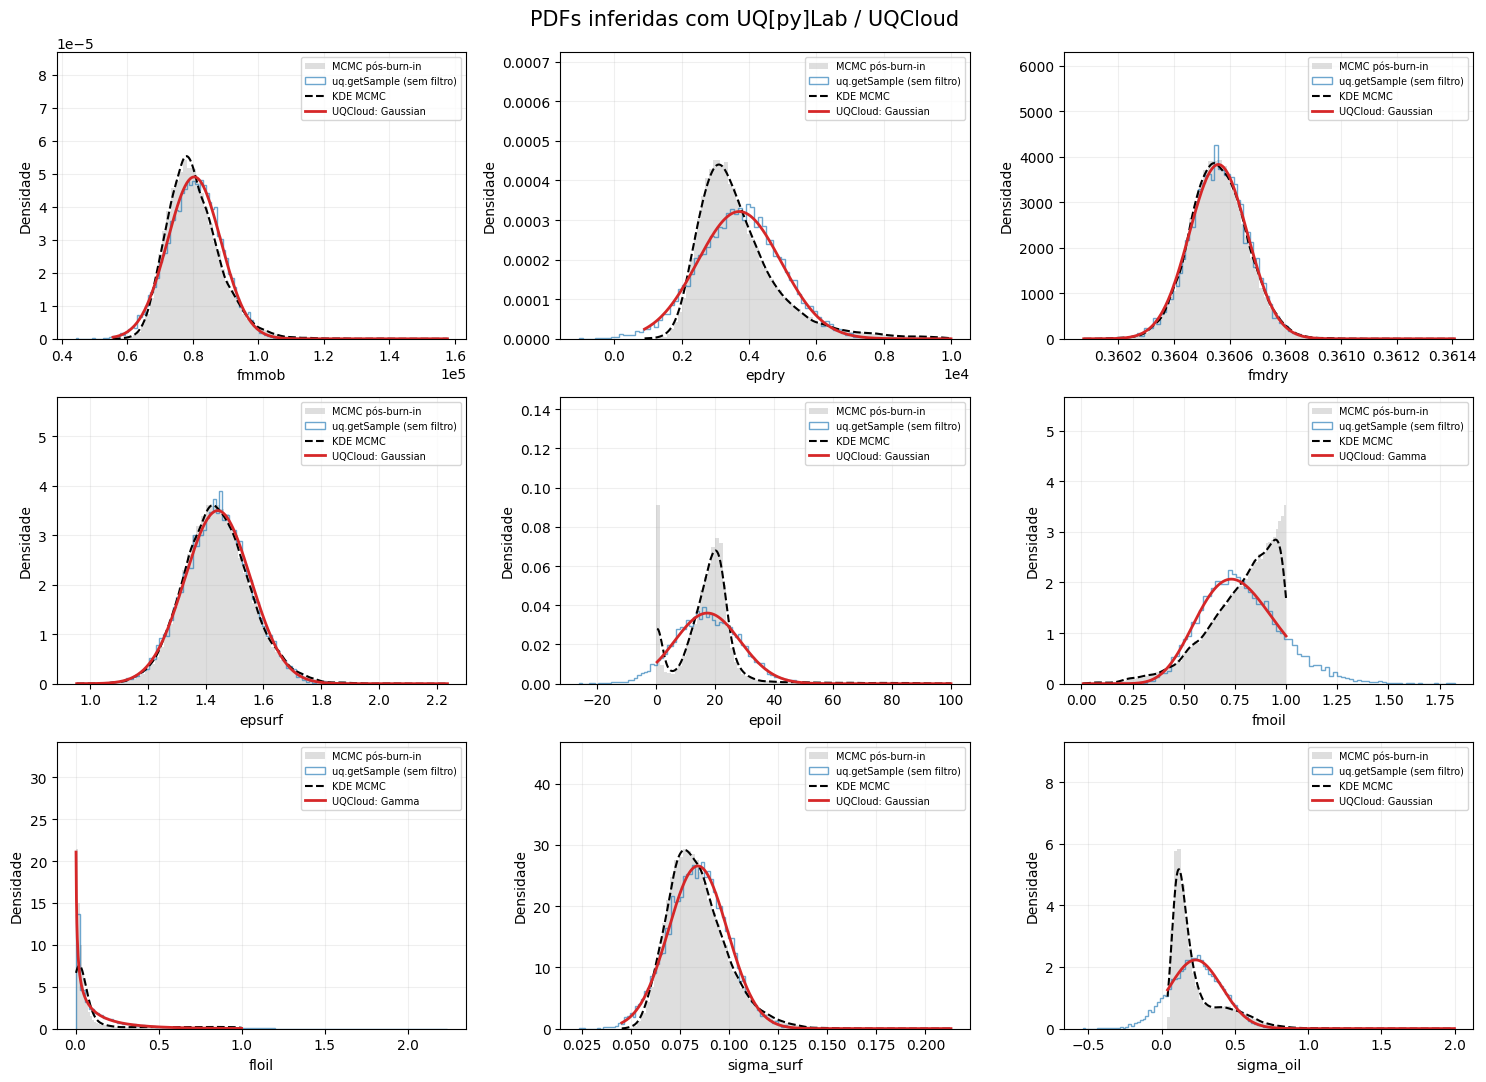

In [5]:
# Sorteios e PDFs avaliados pelo UQCloud; a KDE é calculada localmente.
uq.rng(BASE_SEED + 1000, "twister")
diagnostic_samples = np.asarray(uq.getSample(joint_input, PDF_DIAGNOSTIC_SAMPLES), dtype=float)
if diagnostic_samples.shape != (PDF_DIAGNOSTIC_SAMPLES, len(posterior_names)):
    raise ValueError("Formato inesperado das amostras de diagnóstico UQCloud.")
pdf_grids = []
for name in posterior_names:
    _, edges = np.histogram(posterior_df[name], bins=80)
    pdf_grids.append(np.linspace(edges[0] + (edges[1] - edges[0]) / 4, edges[-1], 400))
pdf_grids = np.column_stack(pdf_grids)
fitted_pdf_values = np.asarray(uq.all_pdf(pdf_grids, joint_marginals), dtype=float)
if fitted_pdf_values.shape != pdf_grids.shape:
    raise ValueError("Formato inesperado das PDFs retornadas por uq.all_pdf.")

pdf_rng = np.random.default_rng(BASE_SEED + 1000)
fig, axes = plt.subplots(3, 3, figsize=(15, 11))
for i, (ax, name) in enumerate(zip(axes.flat, posterior_names)):
    values = posterior_df[name].to_numpy()
    density, _, _ = ax.hist(values, bins=80, density=True, color="0.75", alpha=0.5,
                            label="MCMC pós-burn-in")
    ax.hist(diagnostic_samples[:, i], bins=80, density=True, histtype="step",
            color="tab:blue", alpha=0.65, label="uq.getSample (sem filtro)")
    kde_values = values if len(values) <= KDE_MAX_SAMPLES else pdf_rng.choice(
        values, size=KDE_MAX_SAMPLES, replace=False,
    )
    ax.plot(pdf_grids[:, i], st.gaussian_kde(kde_values)(pdf_grids[:, i]),
            "k--", lw=1.5, label="KDE MCMC")
    family = fitted_marginals[name]["Type"]
    ax.plot(pdf_grids[:, i], fitted_pdf_values[:, i], color="tab:red", lw=2,
            label=f"UQCloud: {family}")
    ax.set(xlabel=name, ylabel="Densidade", ylim=(0, max(density) * 1.6))
    ax.ticklabel_format(axis="x", style="sci", scilimits=(-3, 4), useOffset=False)
    ax.grid(alpha=0.2)
    ax.legend(fontsize=7)
fig.suptitle("PDFs inferidas com UQ[py]Lab / UQCloud", fontsize=15)
fig.tight_layout()
fig.savefig(FIT_OUTPUT_DIR / "fitted_pdfs.png", dpi=160, bbox_inches="tight")
plt.show()


## Amostragem das PDFs e restrições físicas

Sorteamos propostas com `uq.getSample(joint_input, N)`, a partir das PDFs inferidas pelo UQCloud e da cópula independente, seguindo a hipótese de marginais independentes do código de referência. As correlações do MCMC não são preservadas. Mantemos o filtro físico e a reamostragem até obter `N_samples` vetores válidos (`SAMPLING_MODE="resample"`). Em `"discard"`, somente os válidos dentre `N_samples` propostas são simulados.

A rejeição impõe positividade e `0 ≤ floil < fmoil ≤ 1`; isso condiciona a distribuição conjunta e pode alterar os momentos finais. A tabela compara MCMC, PDFs ajustadas e amostras físicas aceitas. `sigma_surf` e `sigma_oil` continuam sendo amostrados como escalas da verossimilhança, sem acrescentar ruído às curvas determinísticas.

In [6]:
def physical_mask(values):
    """Aceita somente parâmetros físicos, sem alterar valores sorteados."""
    p = pd.DataFrame(values, columns=mcmc_statistics.index)
    positive = ["fmmob", "epdry", "epsurf", "epoil", "sigma_surf", "sigma_oil"]
    return (
        np.isfinite(values).all(axis=1)
        & (p[positive] > 0).all(axis=1).to_numpy()
        & p["fmdry"].between(fixed_rp_oil["swc"], 1 - fixed_rp_oil["swc"]).to_numpy()
        & (p["floil"] >= 0).to_numpy()
        & (p["floil"] < p["fmoil"]).to_numpy()
        & (p["fmoil"] <= 1).to_numpy()
    )


if not isinstance(N_samples, (int, np.integer)) or isinstance(N_samples, bool) or N_samples < 1:
    raise ValueError("N_samples deve ser um inteiro positivo.")
if SAMPLING_MODE not in {"resample", "discard"}:
    raise ValueError('SAMPLING_MODE deve ser "resample" ou "discard".')

uq.rng(BASE_SEED, "twister")
accepted_batches = []
n_accepted = 0
n_proposed = 0
MAX_PROPOSALS = max(10000, 1000 * N_samples)
while n_accepted < N_samples and n_proposed < MAX_PROPOSALS:
    # Sorteia cada marginal ajustada; rejeita vetores completos que não são físicos.
    batch_size = min(N_samples - n_accepted, MAX_PROPOSALS - n_proposed)
    proposed = np.asarray(uq.getSample(joint_input, int(batch_size)), dtype=float)
    if proposed.shape != (batch_size, len(posterior_names)):
        raise ValueError("Formato inesperado dos vetores amostrados pelo UQCloud.")
    valid = physical_mask(proposed)
    accepted_batches.append(proposed[valid])
    n_accepted += int(valid.sum())
    n_proposed += batch_size
    if SAMPLING_MODE == "discard":
        break

if n_accepted == 0 or (SAMPLING_MODE == "resample" and n_accepted < N_samples):
    raise RuntimeError("Não foi possível obter as amostras físicas solicitadas.")

parameter_samples = pd.DataFrame(
    np.concatenate(accepted_batches), columns=mcmc_statistics.index,
)
parameter_samples.index.name = "sample"
theta_samples = parameter_samples[FOAM_NAMES].to_numpy()
N_simulated = len(parameter_samples)

sample_statistics = parameter_samples.agg(["mean", "std"]).T
sample_statistics["cv_percent"] = (
    100 * sample_statistics["std"] / sample_statistics["mean"].abs()
)
comparison = (
    mcmc_statistics.add_prefix("MCMC_")
    .join(fitted_statistics[["mean", "std", "cv_percent"]].add_prefix("PDF_"))
    .join(sample_statistics.add_prefix("sample_"))
)
print(f"Propostas: {n_proposed}; rejeitadas: {n_proposed - n_accepted}; simuladas: {N_simulated}")
print("Momentos MCMC, PDFs ajustadas e amostras físicas aceitas:")
print(comparison.to_string(float_format=lambda value: f"{value:.6g}"))


Propostas: 126; rejeitadas: 26; simuladas: 100
Momentos MCMC, PDFs ajustadas e amostras físicas aceitas:
            MCMC_mean   MCMC_std  MCMC_cv_percent  PDF_mean    PDF_std  PDF_cv_percent  sample_mean  sample_std  sample_cv_percent
parameter                                                                                                                         
fmmob         80410.8     8128.4          10.1086   80410.8     8128.4         10.1086      80134.6     8398.01            10.4799
epdry         3708.72    1240.75          33.4548   3708.72    1240.75         33.4548      3628.64     1437.24            39.6084
fmdry        0.360559 0.00010417        0.0288912  0.360559 0.00010417       0.0288912     0.360566  0.00011118           0.030835
epsurf        1.44198   0.114182          7.91839   1.44198   0.114182         7.91839      1.44447    0.114884            7.95337
epoil         17.3497    11.0775          63.8481   17.3497    11.0775         63.8481       20.245     9.764

## Viscosidade aparente versus fração de gás

Ensaios sem óleo, `sor=0`, nas concentrações de 625, 1250 e 2500 mg/L. Cada curva corresponde a um vetor físico amostrado e usa `alpha=0.25`; os pontos são os dados experimentais.

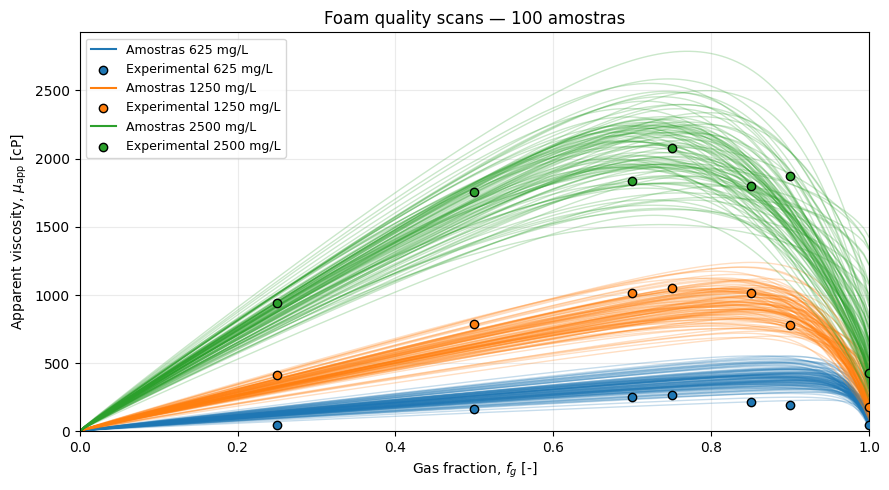

In [7]:
fg_grid = np.linspace(0, 1, N_FG_POINTS)
so_foil_grid = np.linspace(0, 1, N_FOIL_POINTS)
so_oil_grid = np.linspace(so_oil_obs.min(), so_oil_obs.max(), N_SO_POINTS)

mu_fg_samples = {}
for cs in CONCENTRATIONS:
    mu_fg_samples[cs] = np.stack([
        predict(
            theta, fg_grid, np.ones(fg_grid.size, dtype=bool),
            np.full(fg_grid.size, velocity_by_concentration[cs]),
            np.full(fg_grid.size, cs, dtype=float), foam_module_no_oil,
            rp_no_oil, FMSURF, inputs,
        )[0]
        for theta in theta_samples
    ])

fig, ax = plt.subplots(figsize=(9, 5))
for i, cs in enumerate(CONCENTRATIONS):
    color = f"C{i}"
    ax.plot(fg_grid, mu_fg_samples[cs].T, color=color, alpha=ALPHA, lw=1)
    ax.plot([], [], color=color, label=f"Amostras {cs} mg/L")
    ax.scatter(scans[cs][:, 0], scans[cs][:, 1], color=color, edgecolor="black",
               label=f"Experimental {cs} mg/L", zorder=3)
ax.set(xlabel=r"Gas fraction, $f_g$ [-]",
       ylabel=r"Apparent viscosity, $\mu_{\mathrm{app}}$ [cP]",
       title=f"Foam quality scans — {N_simulated} amostras", xlim=(0, 1), ylim=(0, None))
ax.legend(fontsize=9)
ax.grid(alpha=0.25)
fig.tight_layout()
plt.show()


## Viscosidade aparente versus saturação de óleo: saturações experimentais

Usamos os mesmos pares `Sw`, `Sg`, `So` e a concentração de óleo do YAML, como no gráfico de saturações experimentais de `01_estimate.ipynb`. As linhas conectam as previsões nesses pontos; não impõem $f_g=0{,}5$ entre eles.

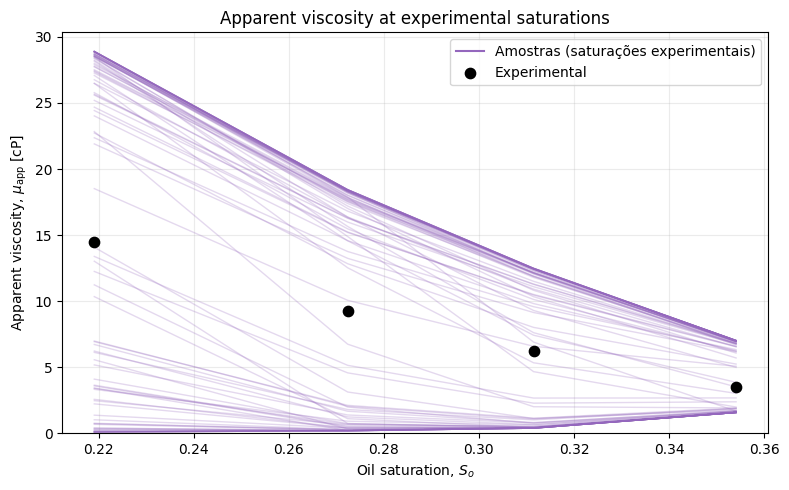

In [8]:
mu_oil_samples = np.stack([
    predict_oil_viscosity(
        theta, foam_module_oil, sw_oil_obs, sg_oil_obs, so_oil_obs,
        inputs, cs_oil_obs, FMSURF,
    )
    for theta in theta_samples
])

fig, ax = plt.subplots(figsize=(8, 5))
ax.plot(so_oil_obs, mu_oil_samples.T, color="tab:purple", alpha=ALPHA, lw=1)
ax.plot([], [], color="tab:purple", label="Amostras (saturações experimentais)")
ax.scatter(so_oil_obs, mu_oil_obs, color="black", s=55, zorder=3, label="Experimental")
ax.set(xlabel=r"Oil saturation, $S_o$",
       ylabel=r"Apparent viscosity, $\mu_{\mathrm{app}}$ [cP]",
       title="Apparent viscosity at experimental saturations", ylim=(0, None))
ax.legend(fontsize=10)
ax.grid(alpha=0.25)
fig.tight_layout()
plt.show()


## Fator de óleo versus saturação de óleo

Calculamos $F_{oil}(S_o)$ com a mesma lei STARS do modelo de referência, usando os parâmetros `epoil`, `floil` e `fmoil` de cada amostra. Não há medições experimentais de $F_{oil}$ no YAML.

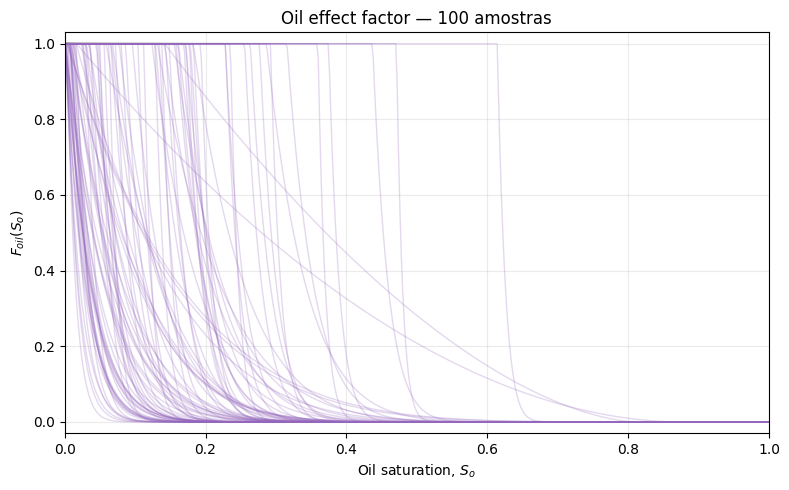

In [9]:
foil_samples = np.stack([
    predict_oil(theta, foam_module_oil, so_foil_grid)
    for theta in theta_samples
])

fig, ax = plt.subplots(figsize=(8, 5))
ax.plot(so_foil_grid, foil_samples.T, color="tab:purple", alpha=ALPHA, lw=1)
ax.set(xlabel=r"Oil saturation, $S_o$", ylabel=r"$F_{oil}(S_o)$",
       title=f"Oil effect factor — {N_simulated} amostras",
       xlim=(0, 1), ylim=(-0.03, 1.03))
ax.grid(alpha=0.25)
fig.tight_layout()
plt.show()


## Viscosidade aparente versus saturação de óleo: código de referência

Aplicamos o procedimento do código fornecido a cada vetor de `theta_samples`:

1. Interpolamos `Sw` e `Sg` experimentais e restringimos os estados locais a uma distância absoluta máxima `SATURATION_TOLERANCE=0.01` de **ambas** as saturações de referência.
2. Buscamos uma raiz com $f_g=0{,}5$ nesse intervalo. Sem raiz, escolhemos entre `N_SATURATION_CANDIDATES=201` candidatos o menor erro em `fg`; empates favorecem a proximidade das saturações experimentais.
3. Também calculamos a curva completa para $f_g=0{,}5$, sem a restrição de proximidade das saturações experimentais.

**Como no gráfico final do código fornecido, as linhas roxas representam a curva completa (`muApp_oil_full`), não a curva local.** Elas podem usar saturações diferentes das experimentais e gerar viscosidades maiores. Para exibir também os trechos locais sem raiz exata, ative `SHOW_NEARBY_CURVES`; eles aparecem em laranja tracejado e podem ter `fg` diferente de 0,5. Pontos sem solução permanecem `NaN`.

`oil_fg_scans` guarda, para cada amostra e ponto, as saturações locais e completas, o erro em `fg`, os fatores de espuma e as mobilidades. Os dados de referência são lidos do mesmo YAML dos outros gráficos.

Curva completa fg=0.5: 9110/10000 pontos
Estados locais com fg=0.5: 148/10000
Estados locais com fg variável: 9852
Pontos sem estado local viável: 0


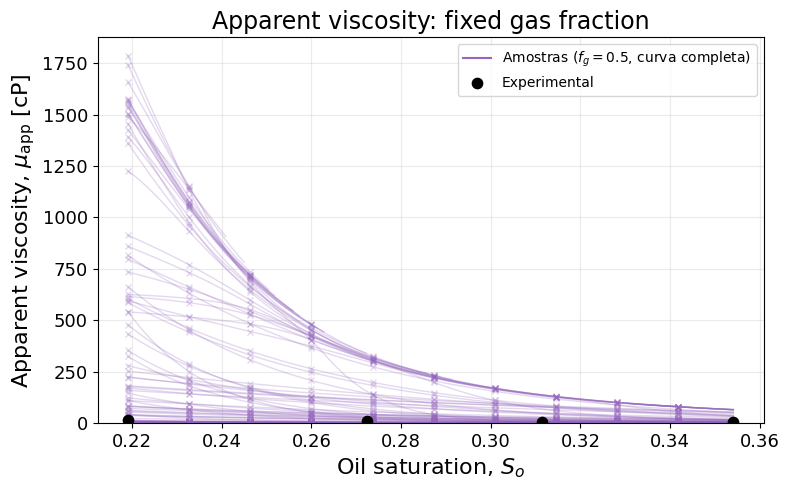

In [10]:
# Reconstrução local e curva completa, seguindo o código fornecido.
oil_saturation_reference = oil_observations.copy()
cs_oil_grid = cs_oil
sw_oil_reference = np.interp(
    so_oil_grid, oil_saturation_reference["So"], oil_saturation_reference["Sw"],
)
sg_oil_reference = np.interp(
    so_oil_grid, oil_saturation_reference["So"], oil_saturation_reference["Sg"],
)
# Interseção das tolerâncias de Sw e Sg, usando Sg = 1 - So - Sw.
sw_candidate_min = np.maximum(
    sw_oil_reference - SATURATION_TOLERANCE,
    1 - so_oil_grid - (sg_oil_reference + SATURATION_TOLERANCE),
)
sw_candidate_max = np.minimum(
    sw_oil_reference + SATURATION_TOLERANCE,
    1 - so_oil_grid - (sg_oil_reference - SATURATION_TOLERANCE),
)


def reconstruct_oil_sample(theta_mu):
    # Primeiro, busca fg alvo apenas perto da trajetória experimental.
    fg_local, sw_local, mu_local = predict_oil_at_fg(
        theta_mu, so_oil_grid, fixed_rp_oil, foam_module_oil, inputs,
        cs_oil_grid, FMSURF, fg_target=FG_TARGET, fg_tolerance=FG_TOLERANCE,
        sw_bounds=(sw_candidate_min, sw_candidate_max),
    )
    matches_fg_target = np.isfinite(fg_local) & np.isclose(
        fg_local, FG_TARGET, atol=FG_TOLERANCE, rtol=0,
    )
    # Preserva raízes exatas; sem raiz, escolhe o melhor candidato local.
    for i in np.flatnonzero(~matches_fg_target):
        so = so_oil_grid[i]
        sw_min = max(fixed_rp_oil["swc"], sw_candidate_min[i])
        sw_max = min(1 - so - fixed_rp_oil["sgr"], sw_candidate_max[i])
        if so < fixed_rp_oil["sor"] or sw_min > sw_max:
            continue
        sw_candidates = np.unique(np.r_[
            np.linspace(sw_min, sw_max, N_SATURATION_CANDIDATES),
            np.clip(sw_oil_reference[i], sw_min, sw_max),
        ])
        sg_candidates = 1 - so - sw_candidates
        fg_candidates, mu_candidates = evaluate_oil_state(
            theta_mu, foam_module_oil, sw_candidates, sg_candidates,
            np.full_like(sw_candidates, so), inputs, cs_oil_grid, FMSURF,
        )
        feasible = (np.isfinite(fg_candidates) & np.isfinite(mu_candidates)
                    & (mu_candidates > 0))
        if not feasible.any():
            continue
        candidate_ids = np.flatnonzero(feasible)
        distance = ((sw_candidates[feasible] - sw_oil_reference[i]) ** 2
                    + (sg_candidates[feasible] - sg_oil_reference[i]) ** 2)
        order = np.lexsort((distance, np.abs(fg_candidates[feasible] - FG_TARGET)))
        chosen = candidate_ids[order[0]]
        sw_local[i] = sw_candidates[chosen]
        fg_local[i] = fg_candidates[chosen]
        mu_local[i] = mu_candidates[chosen]

    sg_local = 1 - so_oil_grid - sw_local
    foil = predict_oil(theta_mu, foam_module_oil, so_oil_grid)
    fdry = 0.5 + np.arctan(theta_mu[1] * (sw_local - theta_mu[2])) / np.pi
    fsurf = min(cs_oil_grid / FMSURF, 1.0) ** theta_mu[3]
    valid_local = np.isfinite(mu_local)
    fallback_local = valid_local & ~matches_fg_target

    # Esta é a curva desenhada em roxo no código de referência: fg fixo global.
    fg_full, sw_full, mu_full = predict_oil_at_fg(
        theta_mu, so_oil_grid, fixed_rp_oil, foam_module_oil, inputs,
        cs_oil_grid, FMSURF, fg_target=FG_TARGET, fg_tolerance=FG_TOLERANCE,
    )
    sg_full = 1 - so_oil_grid - sw_full

    rp = foam_module_oil.coreyBrooks3ph
    mrf = 1.0 + theta_mu[0] * fdry * foil * fsurf
    return pd.DataFrame({
        "So": so_oil_grid,
        "Sw": sw_local, "Sg": sg_local,
        "Sw_reference": sw_oil_reference, "Sg_reference": sg_oil_reference,
        "delta_Sw": sw_local - sw_oil_reference,
        "delta_Sg": sg_local - sg_oil_reference,
        "valid_fg": matches_fg_target,
        "selection": np.select(
            [matches_fg_target, fallback_local],
            ["fg_target", "near_experimental"], default="no_feasible_state",
        ),
        "fg_calculated": fg_local,
        "fg_error": np.abs(fg_local - FG_TARGET),
        "muApp_calculated_cP": mu_local,
        "mobg": rp.krg(sg_local) / (inputs["fluids"]["mug"] * mrf),
        "mobw": rp.krw(sw_local) / inputs["fluids"]["muw"],
        "mobo": rp.kro(so_oil_grid) / inputs["fluids"]["muo"],
        "Fdry": fdry, "Fsurf": fsurf, "Foil": foil,
        "fmmob * Foil": theta_mu[0] * foil,
        "Sw_full": sw_full, "Sg_full": sg_full,
        "fg_full": fg_full, "muApp_full_cP": mu_full,
    })


oil_sample_scans = [reconstruct_oil_sample(theta) for theta in theta_samples]
oil_fg_scans = pd.concat(
    oil_sample_scans, keys=parameter_samples.index, names=["sample", "point"],
)
mu_oil_full_samples = np.stack([scan["muApp_full_cP"].to_numpy() for scan in oil_sample_scans])
mu_oil_nearby_samples = np.stack([
    scan["muApp_calculated_cP"].where(scan["selection"] == "near_experimental").to_numpy()
    for scan in oil_sample_scans
])
total_points = N_simulated * so_oil_grid.size
print(f"Curva completa fg={FG_TARGET}: {np.isfinite(mu_oil_full_samples).sum()}/{total_points} pontos")
print(f"Estados locais com fg={FG_TARGET}: {oil_fg_scans['valid_fg'].sum()}/{total_points}")
print(f"Estados locais com fg variável: {(oil_fg_scans['selection'] == 'near_experimental').sum()}")
print(f"Pontos sem estado local viável: {(oil_fg_scans['selection'] == 'no_feasible_state').sum()}")

fig, ax = plt.subplots(figsize=(8, 5))
ax.plot(so_oil_grid, mu_oil_full_samples.T,
        color="tab:purple", marker="x", markevery=10,
        alpha=ALPHA, linewidth=1, markersize=4)
ax.plot([], [], color="tab:purple", label=fr"Amostras ($f_g={FG_TARGET}$, curva completa)")
if SHOW_NEARBY_CURVES:
    ax.plot(so_oil_grid, mu_oil_nearby_samples.T,
            color="tab:orange", linestyle="--", alpha=ALPHA, linewidth=1)
    ax.plot([], [], color="tab:orange", linestyle="--", label=r"Estados locais ($f_g$ variável)")
ax.scatter(oil_saturation_reference["So"], oil_saturation_reference["muApp"] * 1000,
           color="black", s=55, zorder=3, label="Experimental")
ax.set_xlabel(r"Oil saturation, $S_o$", fontsize=16)
ax.set_ylabel(r"Apparent viscosity, $\mu_{\mathrm{app}}$ [cP]", fontsize=16)
ax.set_title("Apparent viscosity: fixed gas fraction", fontsize=17)
ax.set_ylim(bottom=0)
# ax.set_yscale("log")
ax.tick_params(labelsize=13)
ax.legend(fontsize=10)
ax.grid(alpha=0.25)
fig.tight_layout()
plt.show()
